# 09 — Day-14 Regression: Predicting the Recorded Activity Span (Supporting Experiment)

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## 1. Goal

Can information available by **day 14** predict how long a case's **recorded activity span** will be?

- **Target:** `duration_days` = last event timestamp minus first event timestamp, in days.
- This is the **recorded activity span** in the event log. It is not a verified administrative completion time:
  it includes every recorded event, which may include publication, objection, archiving or later recording steps.

Notebooks 02–05 also predicted `duration_days`, but they used **whole-case** features (for example the total number of events),
which are only known when the case is finished. Here I use **only day-14 features** (from notebooks 07 and 08), so the results
are **not directly comparable** with notebooks 02–05: different information and a different test group.

## 2. Load the Data and Rebuild the Cohort (Same Rules as Notebooks 07 and 08)

- **Completed case:** `case:endDate` is present.
- **Day-14 cutoff:** `prediction_time` = first event + 14 days.
- **Eligible:** the last recorded event is **after** `prediction_time`. This means the recorded event span extends beyond
  day 14; it does **not** prove that the case was formally open at day 14.

In [1]:
import os
import warnings
from pathlib import Path

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
# hide only PM4Py's optional speed-up tip ("Install the optional requirement `r4pm` ..."); other warnings still show
warnings.filterwarnings("ignore", message="Install the optional requirement `r4pm`")

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

# the project folder: works whether Jupyter starts in the notebooks folder or in the project folder
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_root / "data" / "raw" / "BPIC15_1.xes"



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

In [2]:
log = pm4py.read_xes(str(data_path))
df = pm4py.convert_to_dataframe(log)

case_data = df.groupby("case:concept:name").agg(
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)
case_data = case_data[case_data["end_date"].notna()]   # completed cases only

case_data["prediction_time"] = case_data["first_event"] + pd.Timedelta(days=14)
active = case_data[case_data["last_event"] > case_data["prediction_time"]]

print("Completed cases:", len(case_data))
print("Eligible cases (recorded span longer than 14 days):", len(active))

Completed cases: 956
Eligible cases (recorded span longer than 14 days): 917


## 3. Events Recorded by Day 14 and the Seven Count Features

Same helper functions as notebook 08: keep only events timestamped **on or before** each case's day-14 cutoff, then
calculate the seven count features.

In [3]:
def events_by_day14(event_table, cases):
    # keep only events of eligible cases that happened on or before that case's day-14 cutoff
    events = event_table[event_table["case:concept:name"].isin(cases.index)].copy()
    events["prediction_time"] = events["case:concept:name"].map(cases["prediction_time"])
    events["first_event"] = events["case:concept:name"].map(cases["first_event"])
    first14 = events[events["time:timestamp"] <= events["prediction_time"]].copy()
    first14["day"] = (first14["time:timestamp"] - first14["first_event"]).dt.total_seconds() / (24 * 60 * 60)
    return first14

**The seven count features.** `count_columns` fixes their order; `count_features` calculates them for every case from the events kept above.

In [4]:
count_columns = [
    "events_first14",
    "unique_activities_first14",
    "unique_resources_first14",
    "repeated_activities_first14",
    "events_first7",
    "events_days8_14",
    "days_since_last_event",
]


def count_features(first14, cases):
    # the seven count features from notebooks 07 and 08
    first14 = first14.copy()
    first14["in_first7"] = first14["day"] <= 7
    features = first14.groupby("case:concept:name").agg(
        events_first14=("concept:name", "size"),
        unique_activities_first14=("concept:name", "nunique"),
        unique_resources_first14=("org:resource", "nunique"),
        events_first7=("in_first7", "sum"),
        last_event_by_day14=("time:timestamp", "max"),
    )
    features["repeated_activities_first14"] = features["events_first14"] - features["unique_activities_first14"]
    features["events_days8_14"] = features["events_first14"] - features["events_first7"]
    features["days_since_last_event"] = (
        cases.loc[features.index, "prediction_time"] - features["last_event_by_day14"]
    ).dt.total_seconds() / (24 * 60 * 60)
    return features[count_columns]

**Apply the helpers** to the cases and check that no event after the cutoff was used. `long_case` is only used to rebuild the split; `duration_days` is the regression target.

In [5]:
first14 = events_by_day14(df, active)
features = count_features(first14, active)
features["long_case"] = (active.loc[features.index, "duration_days"] > 63).astype(int)   # only used to rebuild the split
features["duration_days"] = active.loc[features.index, "duration_days"]                  # regression target

print("Events recorded by day 14:", len(first14))
print("Latest event used, in days after the case start:", first14["day"].max())
print("Cases with features:", len(features))

Events recorded by day 14: 10930
Latest event used, in days after the case start: 14.0
Cases with features: 917


## 4. The Same Train/Test Split as Notebooks 07 and 08

The split is rebuilt with exactly the same code as notebooks 07 and 08 (stratified by `long_case`, `random_state=42`), so the
regression models are trained and tested on the **same 733 and 184 cases**. `long_case` is only used to rebuild this split;
it is not a feature.

In [6]:
train_ids, test_ids = train_test_split(
    features.index,
    test_size=0.20,
    random_state=42,
    stratify=features["long_case"]
)

print("Training cases:", len(train_ids))
print("Test cases:", len(test_ids))
print("Overlap between train and test:", len(set(train_ids) & set(test_ids)))
print("All eligible cases used exactly once:", sorted(set(train_ids) | set(test_ids)) == sorted(features.index))

Training cases: 733
Test cases: 184
Overlap between train and test: 0
All eligible cases used exactly once: True


## 5. Activity Features (Selected on Training Cases Only)

Same rule as notebook 08: activity codes recorded by day 14 in **10–90% of training cases**, at most the **15 most frequent**,
ties broken alphabetically. Then one 0/1 feature per selected activity ("recorded by day 14").

In [7]:
train_first14 = first14[first14["case:concept:name"].isin(train_ids)]

activity_share = train_first14.groupby("concept:name")["case:concept:name"].nunique() / len(train_ids) * 100
activity_share = activity_share.rename("train_cases_pct").reset_index()
candidates = activity_share[(activity_share["train_cases_pct"] >= 10) & (activity_share["train_cases_pct"] <= 90)]
candidates = candidates.sort_values(["train_cases_pct", "concept:name"], ascending=[False, True])
selected_activities = candidates.head(15)["concept:name"].tolist()

**Turn the chosen activities into 0/1 columns.** `activity_flags` gives 1 if the activity was recorded by the cutoff in that case, otherwise 0.

In [8]:
def activity_flags(first14, activities, case_ids):
    # 1 if the activity was recorded by day 14 in that case, otherwise 0
    flags = pd.DataFrame(index=case_ids)
    for activity in activities:
        cases_with_activity = first14.loc[first14["concept:name"] == activity, "case:concept:name"].unique()
        flags["act_" + activity] = flags.index.isin(cases_with_activity).astype(int)
    return flags

**Add the indicators** for every eligible case.

In [9]:
flags = activity_flags(first14, selected_activities, features.index)
features = features.join(flags)
activity_columns = flags.columns.tolist()

print("Selected activities:", len(selected_activities))
print(selected_activities)

Selected activities: 15
['01_HOOFD_015', '01_HOOFD_020', '01_HOOFD_030_1', '01_HOOFD_030_2', '01_HOOFD_011', '02_DRZ_010', '04_BPT_005', '01_HOOFD_101', '01_HOOFD_061', '01_HOOFD_065_2', '01_HOOFD_065_1', '01_HOOFD_065_0', '01_HOOFD_100_0', '01_HOOFD_040', '01_HOOFD_060']


## 6. Leakage Check

Change the activity and resource of every event **after** each case's day-14 cutoff to fake values (cohort and cutoffs fixed)
and rebuild all features. If the features only use events up to day 14, nothing may change.

This checks the **code**. It does not test the retrospective cohort selection, and it cannot prove that the timestamps reflect when information was really available in the
municipality's system.

In [10]:
changed = df.copy()
after_day14 = changed["time:timestamp"] > changed["case:concept:name"].map(active["prediction_time"])
changed.loc[after_day14, "concept:name"] = "FAKE_ACTIVITY"
changed.loc[after_day14, "org:resource"] = "FAKE_RESOURCE"

changed_first14 = events_by_day14(changed, active)
changed_features = count_features(changed_first14, active).join(
    activity_flags(changed_first14, selected_activities, features.index)
)

print("Events changed:", after_day14.sum())
print("All features unchanged:", changed_features.equals(features[count_columns + activity_columns]))

Events changed: 32715
All features unchanged: True


## 7. Train the Four Approaches

All four use the same training cases and are tested on the same 184 test cases. Settings are fixed (no tuning).

- **A. Median baseline:** predicts the median training `duration_days` for every case.
- **B. Linear Regression, 7 count features** (`StandardScaler` + `LinearRegression`).
- **C. Linear Regression, 7 counts + activity features** (same pipeline).
- **D. Decision Tree, 7 counts + activity features** (`max_depth=3`, `min_samples_leaf=20`).

The scaler is part of the pipeline, so it is fitted on the training data only.

In [11]:
y_train = features.loc[train_ids, "duration_days"]
y_test = features.loc[test_ids, "duration_days"]
X_train_7, X_test_7 = features.loc[train_ids, count_columns], features.loc[test_ids, count_columns]
X_train_all = features.loc[train_ids, count_columns + activity_columns]
X_test_all = features.loc[test_ids, count_columns + activity_columns]

model_a = DummyRegressor(strategy="median").fit(X_train_7, y_train)
model_b = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train_7, y_train)
model_c = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train_all, y_train)
model_d = DecisionTreeRegressor(max_depth=3, min_samples_leaf=20, random_state=42).fit(X_train_all, y_train)

print(f"Median training duration (baseline prediction): {y_train.median():.2f} days")

Median training duration (baseline prediction): 64.41 days


## 8. Evaluate

- **MAE (main metric):** the average absolute error in days, i.e. how many days a prediction is wrong on average.
- **RMSE:** like MAE, but large errors count more.
- **R²:** share of the variation in `duration_days` explained (0 = no better than predicting the mean).

Every eligible case lasts more than 14 days, so predictions **below 14 days** are impossible values. I count them and do
**not** clip them.

In [12]:
approaches = {
    "A. Median baseline": (model_a, X_train_7, X_test_7),
    "B. LinReg, 7 counts": (model_b, X_train_7, X_test_7),
    "C. LinReg, counts + activities": (model_c, X_train_all, X_test_all),
    "D. Tree, counts + activities": (model_d, X_train_all, X_test_all),
}

**Predict and score each approach** on the training cases and on the test cases.

In [13]:
rows = []
test_predictions = {}
for name, (model, X_tr, X_te) in approaches.items():
    pred_train = model.predict(X_tr)
    pred_test = model.predict(X_te)
    test_predictions[name] = pred_test
    rows.append({
        "Approach": name,
        "Test MAE": mean_absolute_error(y_test, pred_test),
        "Test RMSE": mean_squared_error(y_test, pred_test) ** 0.5,
        "Test R²": r2_score(y_test, pred_test),
        "Train MAE": mean_absolute_error(y_train, pred_train),
        "Test predictions < 14 days": int((pred_test < 14).sum()),
    })

results = pd.DataFrame(rows).set_index("Approach")
results.round(2)

,Test MAE,Test RMSE,Test R²,Train MAE,Test predictions < 14 days
Approach,,,,,
A. Median baseline,70.75,173.77,-0.09,52.85,0
"B. LinReg, 7 counts",78.24,164.93,0.02,61.30,0
"C. LinReg, counts + activities",76.90,161.59,0.06,59.13,1
"D. Tree, counts + activities",81.27,168.22,-0.02,58.83,0


Train MAE and test MAE can only be compared fairly if the two groups have similar targets. A quick look at
`duration_days` in both groups:

In [14]:
pd.DataFrame({"training cases": y_train.describe(), "test cases": y_test.describe()}).round(1)

,training cases,test cases
count,733.0,184.0
mean,98.8,114.6
std,102.6,166.8
min,14.6,14.4
25%,50.0,49.0
50%,64.4,64.0
75%,104.0,104.0
max,998.0,1486.0


## 9. Actual vs Predicted (Lowest Test MAE)

Lowest test MAE: A. Median baseline


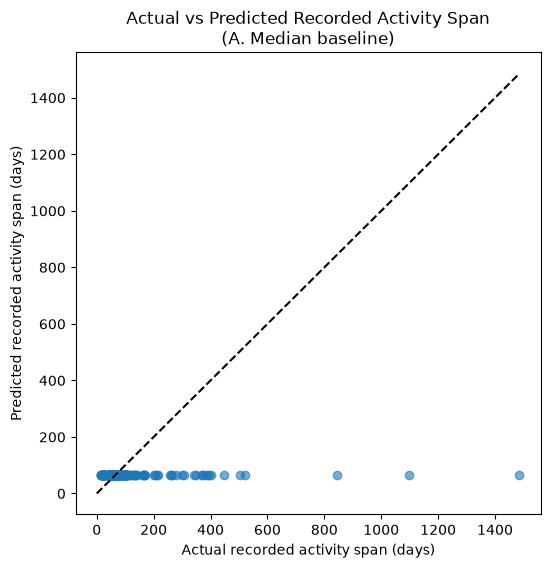

In [15]:
best = results["Test MAE"].idxmin()
print("Lowest test MAE:", best)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, test_predictions[best], alpha=0.6)
plt.plot([0, y_test.max()], [0, y_test.max()], linestyle="--", color="black")
plt.title(f"Actual vs Predicted Recorded Activity Span\n({best})")
plt.xlabel("Actual recorded activity span (days)")
plt.ylabel("Predicted recorded activity span (days)")
plt.show()

If the median baseline has the lowest MAE, all points lie on one flat line, because it predicts the same value for every case.

## 10. Interpretation

**No model beats the median baseline on MAE.** Predicting the median training span (64.4 days) for every case gives a test
MAE of 70.75 days. All three models make larger average errors: 76.90 (C), 78.24 (B) and 81.27 days (D).

**Do the activity features help Linear Regression?** A little, compared with the seven counts alone (C vs B): MAE
78.24 → 76.90, RMSE 164.93 → 161.59, R² 0.02 → 0.06. But C is still worse than the baseline on MAE, and an R² of 0.06
means it explains almost none of the variation.

**Does the simple tree improve on the baseline?** No. Its test MAE (81.27) is the worst of the four, and its R² (−0.02) is
below zero. Its training MAE (58.83) is much lower than its test MAE.

**Why the test errors are higher for every approach, even the baseline:** the two groups have the same middle (median about
64 days, the same quartiles), but the test group has a heavier tail of very long cases (standard deviation 166.8 vs 102.6
days; the longest case, 1,486 days, is in the test group). A few very long cases make a large difference on 184 test cases.

**RMSE tells a slightly different story:** the Linear Regression models have a lower RMSE than the baseline (about 162–165 vs
174), so they reduce some of the largest errors, but they do this at the cost of a higher average error (MAE).

**Impossible predictions:** only one prediction (model C) is below 14 days, which is impossible for this cohort. It was not
changed.

**Conclusion:** with these day-14 features, these simple models **do not predict the recorded activity span better than a
constant median**. The test set is small and has a heavy tail, so the exact numbers are uncertain, but there is no evidence
here that the day-14 information is useful for predicting the span in days.

## 11. Limitations

- This is an **exploratory comparison** on a small test set (184 cases) that was already examined in notebooks 07 and 08.
- The target includes **all recorded events**, which may include publication, objection, archiving or later recording steps;
  it is not a verified administrative completion time.
- Event timestamps are **assumed** to show information available by the day-14 cutoff; the dataset does not establish this
  conclusively.
- The leakage check verifies the **feature code**, not the real-world availability of the information.
- Results concern **one Dutch municipality** and cannot establish performance for SPAR or Montenegro.
- These results are **not directly comparable** with notebooks 02–05, which used whole-case features and a different test group.